In [1]:

# Install required libraries
!pip install pandas numpy matplotlib seaborn scipy -q

print("Libraries installed successfully!")


Libraries installed successfully!


In [2]:

# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Set visualization style
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("All libraries imported successfully!")


All libraries imported successfully!


In [5]:

from google.colab import files

uploaded = files.upload()

# Read CSV file
df = pd.read_csv("train.csv")

# Display first 5 records
df.head()


Saving train.csv to train.csv


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [6]:

# STEP 6: Dataset Understanding

# 1. Check rows and columns
print("Dataset Shape:", df.shape)

# 2. Check column names
print("\nColumn Names:")
print(df.columns.tolist())

# 3. Check data types and missing values
print("\nDataset Information:")
df.info()

# 4. Statistical summary
print("\nStatistical Summary:")
display(df.describe())


Dataset Shape: (1460, 81)

Column Names:
['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond', 'PavedDrive', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPo

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [7]:

# STEP 7: Missing Values Analysis

missing_values = df.isnull().sum()

missing_percentage = (missing_values / len(df)) * 100

missing_report = pd.DataFrame({
    "Missing Values": missing_values,
    "Percentage": missing_percentage
})

missing_report = missing_report[
    missing_report["Missing Values"] > 0
].sort_values(
    by="Missing Values",
    ascending=False
)

display(missing_report)


,Missing Values,Percentage
PoolQC,1453,99.520548
MiscFeature,1406,96.301370
Alley,1369,93.767123
Fence,1179,80.753425
MasVnrType,872,59.726027
FireplaceQu,690,47.260274
LotFrontage,259,17.739726
GarageType,81,5.547945
GarageYrBlt,81,5.547945
GarageFinish,81,5.547945


In [8]:

# STEP 8: Classify Variables

# Numerical columns
numeric_cols = df.select_dtypes(
    include=["number"]
).columns.tolist()

# Categorical columns
categorical_cols = df.select_dtypes(
    include=["object"]
).columns.tolist()

# Ordinal variables
ordinal_map = {
    "ExterQual": ["Po", "Fa", "TA", "Gd", "Ex"],
    "KitchenQual": ["Po", "Fa", "TA", "Gd", "Ex"]
}

# Convert ordinal columns into ordered categories
for column, order in ordinal_map.items():
    df[column] = pd.Categorical(
        df[column],
        categories=order,
        ordered=True
    )

print("Numerical Columns:", len(numeric_cols))
print("Categorical Columns:", len(categorical_cols))
print("Ordinal Columns:", list(ordinal_map.keys()))


Numerical Columns: 38
Categorical Columns: 43
Ordinal Columns: ['ExterQual', 'KitchenQual']


In [9]:

# Create variable classification summary

variable_summary = []

for column in df.columns:

    if column in ordinal_map or column == "OverallQual":
        variable_type = "Ordinal"

    elif column in numeric_cols:
        variable_type = "Numerical"

    else:
        variable_type = "Categorical"

    variable_summary.append({
        "Column": column,
        "Type": variable_type,
        "Unique Values": df[column].nunique(),
        "Example Values": df[column].dropna().unique()[:5].tolist()
    })

variable_summary = pd.DataFrame(variable_summary)

display(variable_summary)


,Column,Type,Unique Values,Example Values
0,Id,Numerical,1460,"[1, 2, 3, 4, 5]"
1,MSSubClass,Numerical,15,"[60, 20, 70, 50, 190]"
2,MSZoning,Categorical,5,"[RL, RM, C (all), FV, RH]"
3,LotFrontage,Numerical,110,"[65.0, 80.0, 68.0, 60.0, 84.0]"
4,LotArea,Numerical,1073,"[8450, 9600, 11250, 9550, 14260]"
...,...,...,...,...
76,MoSold,Numerical,12,"[2, 5, 9, 12, 10]"
77,YrSold,Numerical,5,"[2008, 2007, 2006, 2009, 2010]"
78,SaleType,Categorical,9,"[WD, New, COD, ConLD, ConLI]"
79,SaleCondition,Categorical,6,"[Normal, Abnorml, Partial, AdjLand, Alloca]"


3. Descriptive Statistics

In this section, we calculate the central tendency and spread of house prices, living area and lot area using mean, median, mode, standard deviation, variance and other statistical measures.

In [10]:

# STEP 10: Descriptive Statistics

# Display summary of all numerical columns
display(df.describe())


,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [11]:

# Calculate statistics for important columns

columns = ["SalePrice", "GrLivArea", "LotArea"]

for column in columns:

    print("\n==========", column, "==========")

    mean = df[column].mean()
    median = df[column].median()
    mode = df[column].mode().iloc[0]

    std = df[column].std()
    variance = df[column].var()

    data_range = df[column].max() - df[column].min()

    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)
    iqr = q3 - q1

    skewness = df[column].skew()
    kurtosis = df[column].kurt()

    print("Mean:", mean)
    print("Median:", median)
    print("Mode:", mode)
    print("Standard Deviation:", std)
    print("Variance:", variance)
    print("Range:", data_range)
    print("IQR:", iqr)
    print("Skewness:", skewness)
    print("Kurtosis:", kurtosis)



========== SalePrice ==========
Mean: 180921.19589041095
Median: 163000.0
Mode: 140000
Standard Deviation: 79442.50288288663
Variance: 6311111264.297451
Range: 720100
IQR: 84025.0
Skewness: 1.8828757597682129
Kurtosis: 6.536281860064529

========== GrLivArea ==========
Mean: 1515.463698630137
Median: 1464.0
Mode: 864
Standard Deviation: 525.4803834232027
Variance: 276129.63336259616
Range: 5308
IQR: 647.25
Skewness: 1.3665603560164552
Kurtosis: 4.895120580693174

========== LotArea ==========
Mean: 10516.828082191782
Median: 9478.5
Mode: 7200
Standard Deviation: 9981.264932379147
Variance: 99625649.6503417
Range: 213945
IQR: 4048.0
Skewness: 12.207687851233496
Kurtosis: 203.24327101886033


In [12]:

# Categorical Analysis

print("Neighborhood Frequency:")
display(df["Neighborhood"].value_counts())

print("\nMost Common Neighborhood:")
print(df["Neighborhood"].mode()[0])

print("\nHouse Style Frequency:")
display(df["HouseStyle"].value_counts())

print("\nMost Common House Style:")
print(df["HouseStyle"].mode()[0])


Neighborhood Frequency:


,count
Neighborhood,
NAmes,225
CollgCr,150
OldTown,113
Edwards,100
Somerst,86
Gilbert,79
NridgHt,77
Sawyer,74
NWAmes,73



Most Common Neighborhood:
NAmes

House Style Frequency:


,count
HouseStyle,
1Story,726
2Story,445
1.5Fin,154
SLvl,65
SFoyer,37
1.5Unf,14
2.5Unf,11
2.5Fin,8



Most Common House Style:
1Story


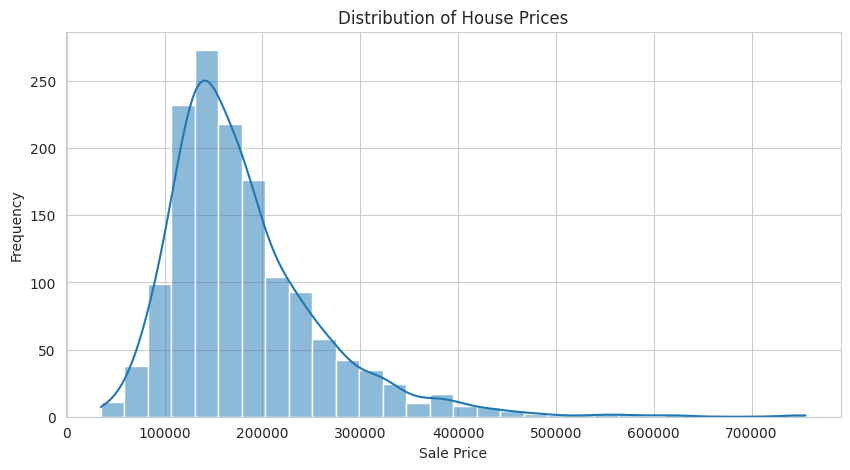

In [13]:

# STEP 14: Histogram and KDE

plt.figure(figsize=(10, 5))

sns.histplot(
    df["SalePrice"],
    bins=30,
    kde=True
)

plt.title("Distribution of House Prices")
plt.xlabel("Sale Price")
plt.ylabel("Frequency")

plt.show()


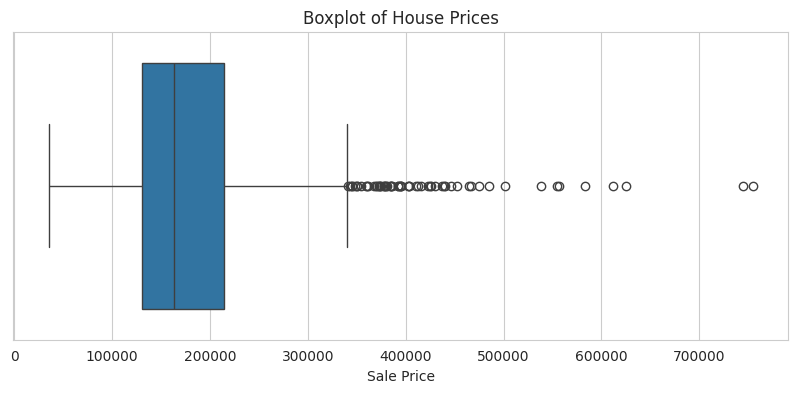

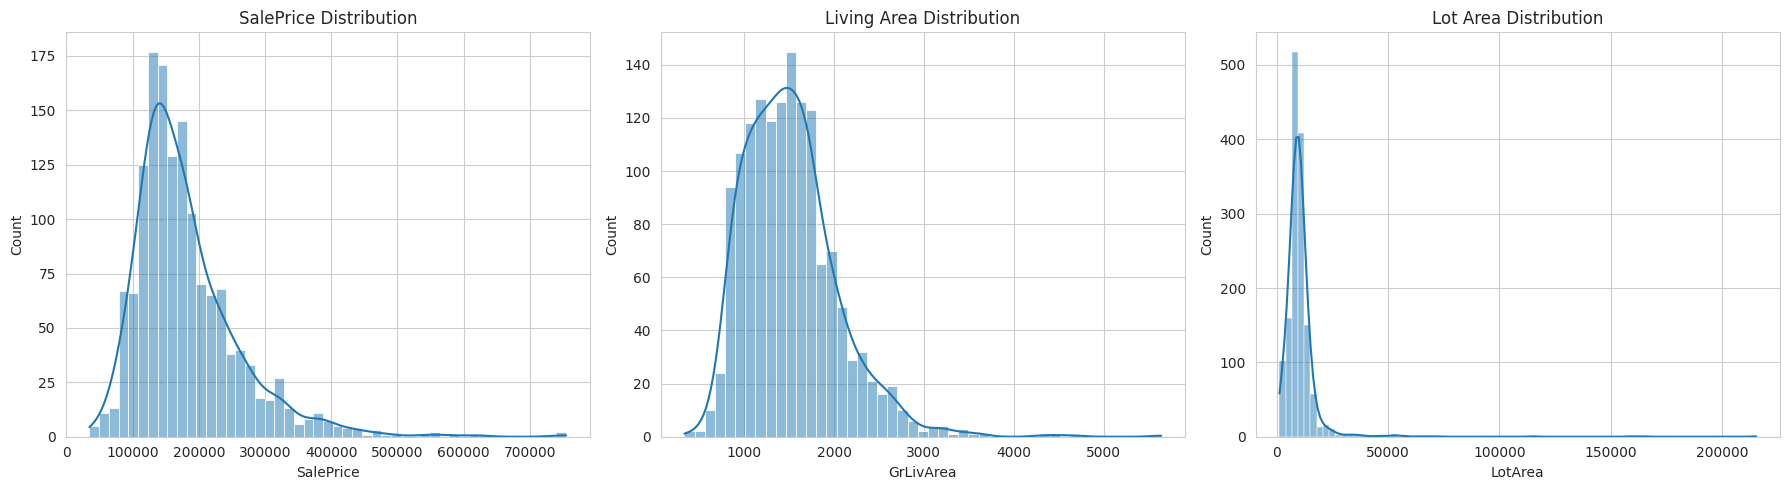

In [15]:

# STEP 15: Boxplot

plt.figure(figsize=(10, 4))

sns.boxplot(x=df["SalePrice"])

plt.title("Boxplot of House Prices")
plt.xlabel("Sale Price")

plt.show()

# Compare numerical distributions

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df["SalePrice"], kde=True, ax=axes[0])
axes[0].set_title("SalePrice Distribution")

sns.histplot(df["GrLivArea"], kde=True, ax=axes[1])
axes[1].set_title("Living Area Distribution")

sns.histplot(df["LotArea"], kde=True, ax=axes[2])
axes[2].set_title("Lot Area Distribution")

plt.tight_layout()
plt.show()



In [19]:

# STEP 17: Correlation Analysis

# Select numerical columns and exclude ID
numeric_data = df.select_dtypes(include=["number"]).drop(
    columns=["Id"],
    errors="ignore"
)

# Calculate correlation matrix
correlation_matrix = numeric_data.corr()

# Display correlation with SalePrice
saleprice_corr = correlation_matrix["SalePrice"].sort_values(
    ascending=False
)

display(saleprice_corr)





,SalePrice
SalePrice,1.000000
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897


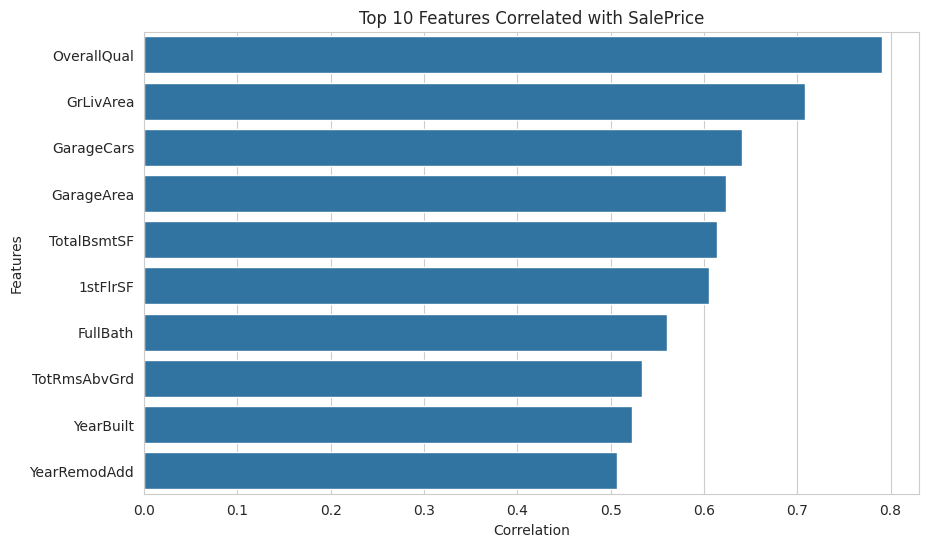

In [20]:

# STEP 18: Top 10 Features Related to SalePrice

top_correlations = saleprice_corr.drop("SalePrice").head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_correlations.values,
    y=top_correlations.index
)

plt.title("Top 10 Features Correlated with SalePrice")
plt.xlabel("Correlation")
plt.ylabel("Features")

plt.show()


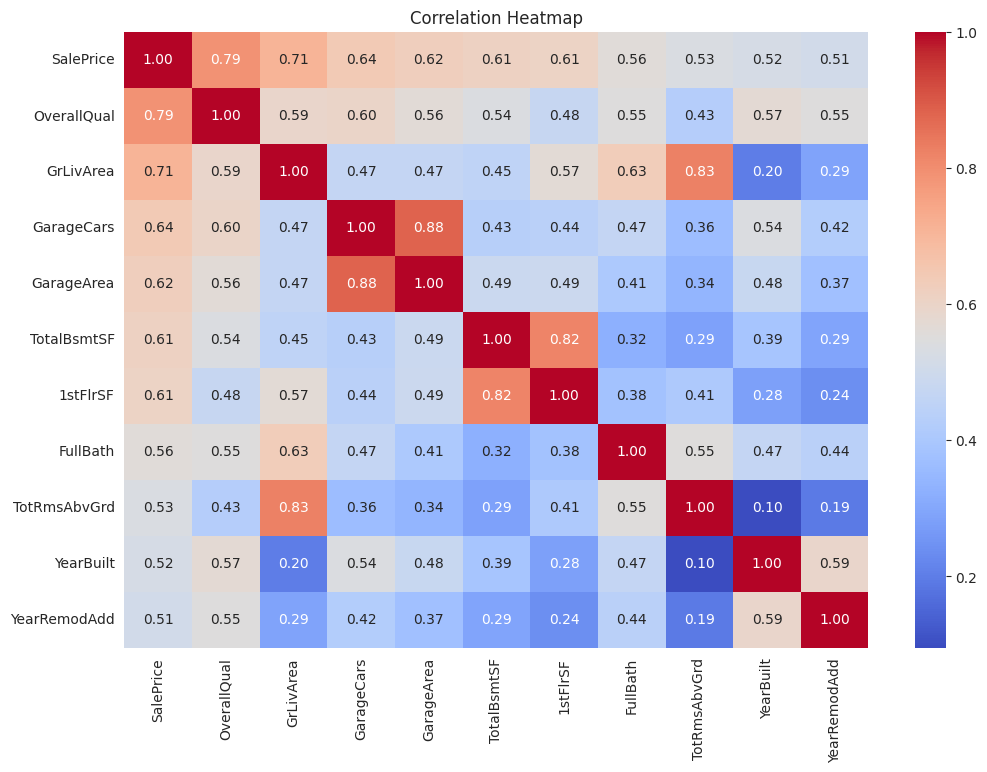

In [21]:

# STEP 19: Correlation Heatmap

top_features = saleprice_corr.abs().sort_values(
    ascending=False
).head(11).index

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_data[top_features].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()


In [22]:

# STEP 21: Outlier Detection Using IQR

outlier_columns = ["SalePrice", "GrLivArea", "LotArea"]

for column in outlier_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_limit) |
        (df[column] > upper_limit)
    ]

    print("\nColumn:", column)
    print("Lower Limit:", lower_limit)
    print("Upper Limit:", upper_limit)
    print("Number of Outliers:", len(outliers))



Column: SalePrice
Lower Limit: 3937.5
Upper Limit: 340037.5
Number of Outliers: 61

Column: GrLivArea
Lower Limit: 158.625
Upper Limit: 2747.625
Number of Outliers: 31

Column: LotArea
Lower Limit: 1481.5
Upper Limit: 17673.5
Number of Outliers: 69


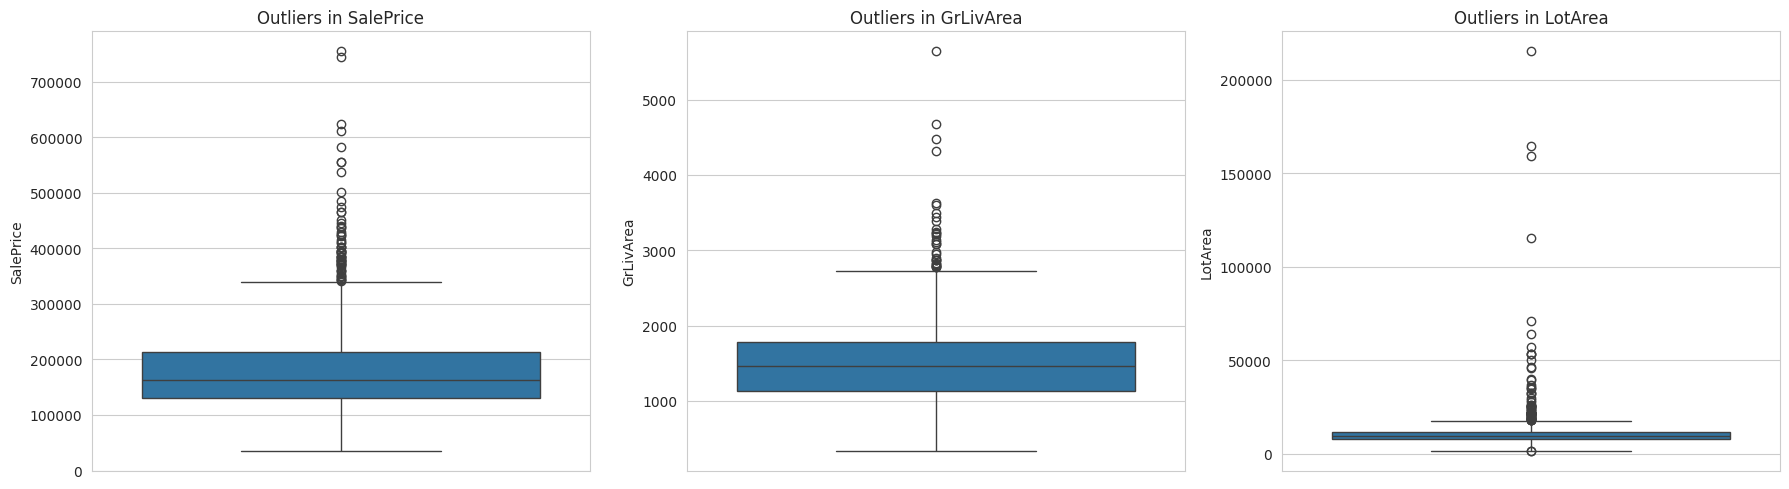

In [23]:

# STEP 22: Outlier Visualization

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, column in enumerate(outlier_columns):

    sns.boxplot(
        y=df[column],
        ax=axes[i]
    )

    axes[i].set_title(f"Outliers in {column}")

plt.tight_layout()
plt.show()


In [24]:

# STEP 23: Outlier Summary

outlier_summary = []

for column in outlier_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = (
        (df[column] < lower) |
        (df[column] > upper)
    ).sum()

    outlier_summary.append({
        "Feature": column,
        "Lower Limit": lower,
        "Upper Limit": upper,
        "Outlier Count": count
    })

display(pd.DataFrame(outlier_summary))


,Feature,Lower Limit,Upper Limit,Outlier Count
0,SalePrice,3937.500,340037.500,61
1,GrLivArea,158.625,2747.625,31
2,LotArea,1481.500,17673.500,69


In [25]:

# STEP 25: Create a Clean Dataset

# Keep original dataset unchanged
cleaned_df = df.copy()

print("Original Dataset:", df.shape)
print("Clean Dataset:", cleaned_df.shape)

print("\nTotal Missing Values Before Cleaning:")
print(cleaned_df.isnull().sum().sum())


Original Dataset: (1460, 81)
Clean Dataset: (1460, 81)

Total Missing Values Before Cleaning:
7829


In [26]:

# STEP 26: Handle Structural Missing Values

absence_columns = [
    "PoolQC",
    "MiscFeature",
    "Alley",
    "Fence",
    "FireplaceQu",
    "GarageType",
    "GarageFinish",
    "GarageQual",
    "GarageCond",
    "BsmtQual",
    "BsmtCond",
    "BsmtExposure",
    "BsmtFinType1",
    "BsmtFinType2",
    "MasVnrType"
]

for column in absence_columns:
    if column in cleaned_df.columns:
        cleaned_df[column] = cleaned_df[column].fillna("None")

print("Categorical missing values handled!")


Categorical missing values handled!


In [27]:

# STEP 27: Handle Numerical Missing Values

# Select numerical columns
numeric_columns = cleaned_df.select_dtypes(
    include=["number"]
).columns

# Fill missing values with median
for column in numeric_columns:
    median_value = cleaned_df[column].median()
    cleaned_df[column] = cleaned_df[column].fillna(median_value)

print("Numerical missing values handled!")

# Check remaining missing values
print("Total Missing Values:",
      cleaned_df.isnull().sum().sum())


Numerical missing values handled!
Total Missing Values: 1


In [28]:

# STEP 28: Find Remaining Missing Values

missing_columns = cleaned_df.columns[
    cleaned_df.isnull().any()
]

print("Columns with missing values:")

for column in missing_columns:
    print(column, ":", cleaned_df[column].isnull().sum())

# Fill remaining missing values
for column in missing_columns:
    if cleaned_df[column].dtype == "object":
        cleaned_df[column] = cleaned_df[column].fillna("None")
    else:
        cleaned_df[column] = cleaned_df[column].fillna(
            cleaned_df[column].median()
        )

print("\nRemaining Missing Values:",
      cleaned_df.isnull().sum().sum())


Columns with missing values:
Electrical : 1

Remaining Missing Values: 0


In [29]:

# STEP 29: Final Data Cleaning Verification

# 1. Check dataset shape
print("Dataset Shape:", cleaned_df.shape)

# 2. Check missing values
print("\nTotal Missing Values:",
      cleaned_df.isnull().sum().sum())

# 3. Check duplicate rows
print("\nDuplicate Rows:",
      cleaned_df.duplicated().sum())

# 4. Check data types
print("\nData Types:")
print(cleaned_df.dtypes.value_counts())

# 5. Display cleaned dataset
print("\nCleaned Dataset Preview:")
display(cleaned_df.head())

print("\nData Cleaning Verification Completed!")


Dataset Shape: (1460, 81)

Total Missing Values: 0

Duplicate Rows: 0

Data Types:
object      41
int64       35
float64      3
category     2
Name: count, dtype: int64

Cleaned Dataset Preview:


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,None,Reg,Lvl,AllPub,...,0,None,None,None,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,None,Reg,Lvl,AllPub,...,0,None,None,None,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,None,IR1,Lvl,AllPub,...,0,None,None,None,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,None,IR1,Lvl,AllPub,...,0,None,None,None,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,None,IR1,Lvl,AllPub,...,0,None,None,None,0,12,2008,WD,Normal,250000



Data Cleaning Verification Completed!


In [30]:

# STEP 30: Outlier Detection using IQR

import pandas as pd

# Select important numerical columns
columns = ["SalePrice", "GrLivArea", "LotArea",
           "TotalBsmtSF", "GarageArea"]

outlier_report = []

for column in columns:

    Q1 = cleaned_df[column].quantile(0.25)
    Q3 = cleaned_df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = cleaned_df[
        (cleaned_df[column] < lower_limit) |
        (cleaned_df[column] > upper_limit)
    ]

    outlier_report.append({
        "Column": column,
        "Lower Limit": lower_limit,
        "Upper Limit": upper_limit,
        "Outliers": len(outliers)
    })

outlier_report = pd.DataFrame(outlier_report)

display(outlier_report)


,Column,Lower Limit,Upper Limit,Outliers
0,SalePrice,3937.500,340037.500,61
1,GrLivArea,158.625,2747.625,31
2,LotArea,1481.500,17673.500,69
3,TotalBsmtSF,42.000,2052.000,61
4,GarageArea,-27.750,938.250,21


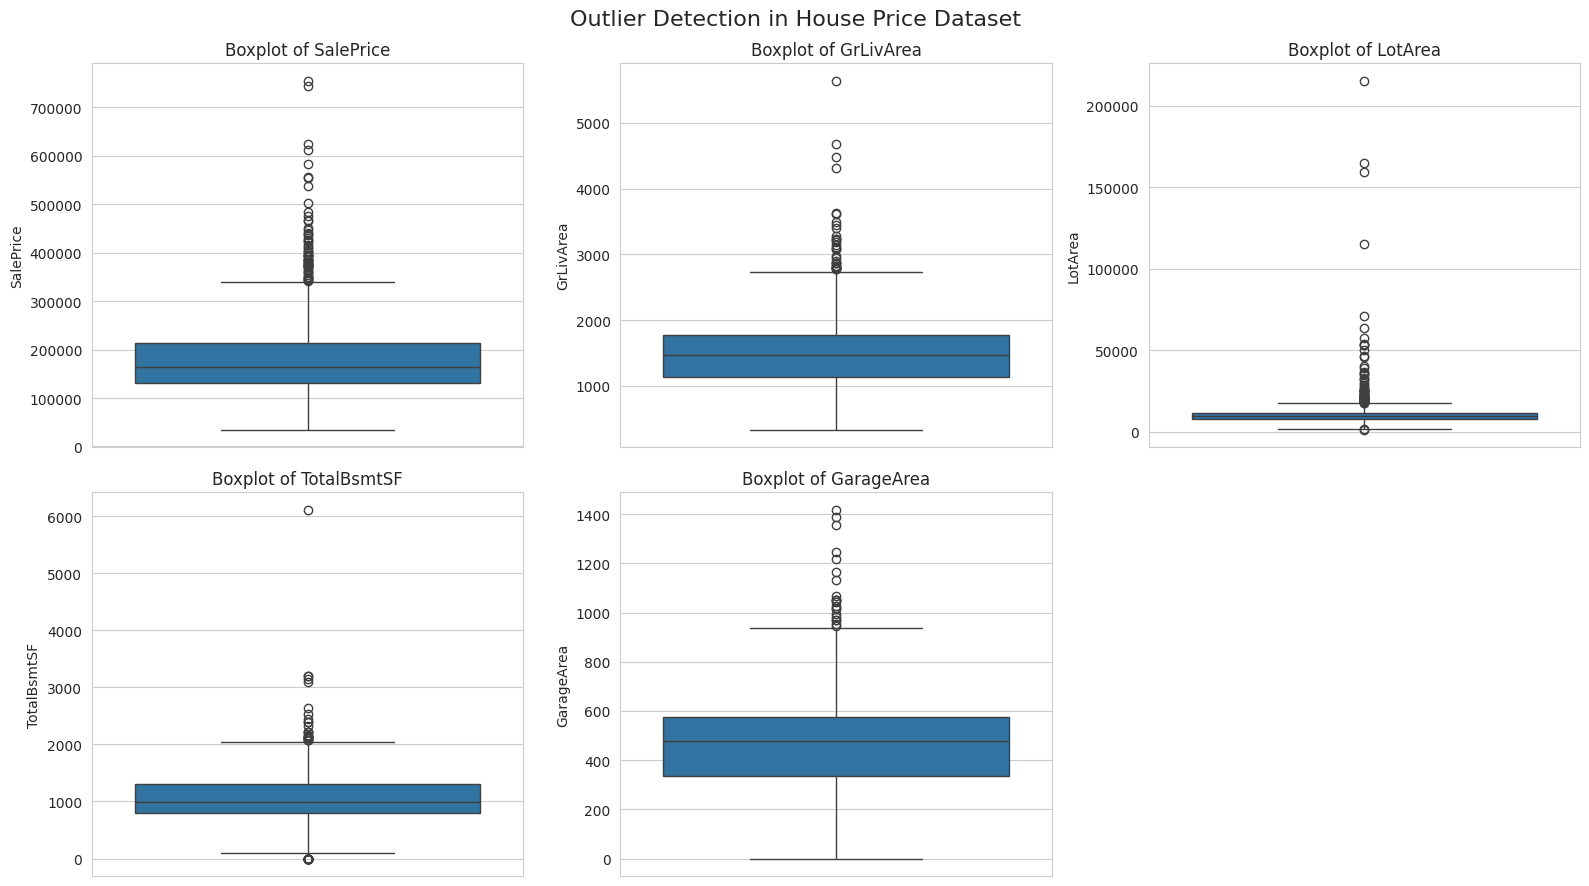

In [31]:

# STEP 31: Outlier Visualization using Boxplots

import matplotlib.pyplot as plt
import seaborn as sns

outlier_columns = [
    "SalePrice",
    "GrLivArea",
    "LotArea",
    "TotalBsmtSF",
    "GarageArea"
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

axes = axes.flatten()

for i, column in enumerate(outlier_columns):

    sns.boxplot(
        y=cleaned_df[column],
        ax=axes[i]
    )

    axes[i].set_title(f"Boxplot of {column}")
    axes[i].set_ylabel(column)

# Remove unused subplot
fig.delaxes(axes[5])

plt.suptitle("Outlier Detection in House Price Dataset",
             fontsize=16)

plt.tight_layout()
plt.show()


Correlation with SalePrice:


,SalePrice
SalePrice,1.000000
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897


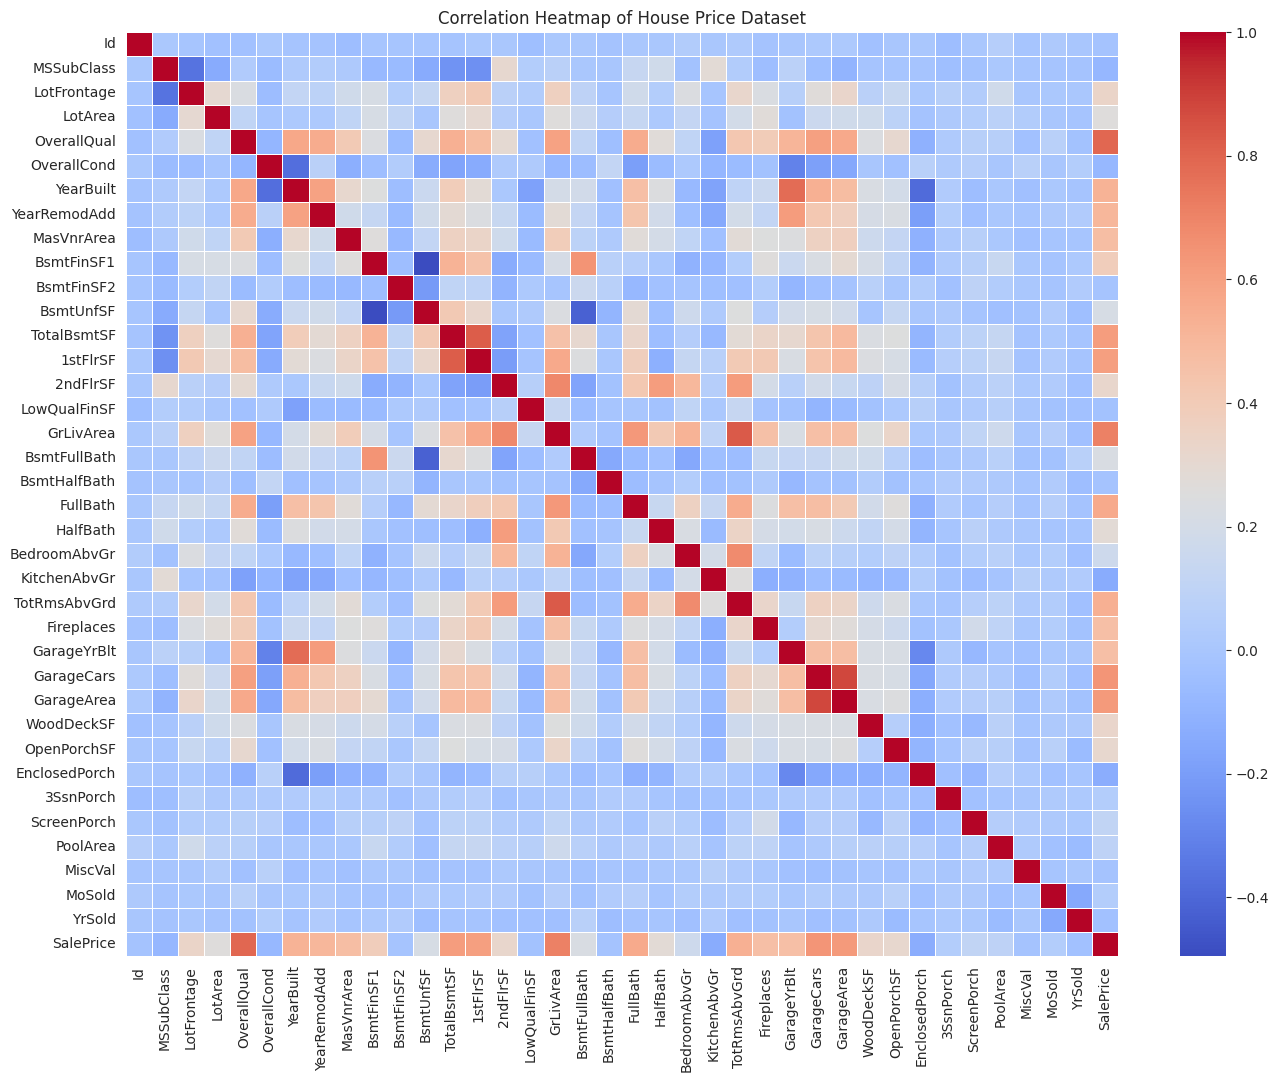

In [32]:
# STEP 32: Correlation Analysis

# Select numerical columns
numerical_df = cleaned_df.select_dtypes(include=['int64', 'float64'])

# Calculate correlation matrix
correlation_matrix = numerical_df.corr()

# Display correlation with SalePrice
saleprice_corr = correlation_matrix['SalePrice'].sort_values(ascending=False)

print("Correlation with SalePrice:")
display(saleprice_corr)

# Plot correlation heatmap
plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    cmap='coolwarm',
    annot=False,
    linewidths=0.5
)

plt.title("Correlation Heatmap of House Price Dataset")
plt.show()

Important Features for House Price Prediction:


,SalePrice
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897
YearRemodAdd,0.507101


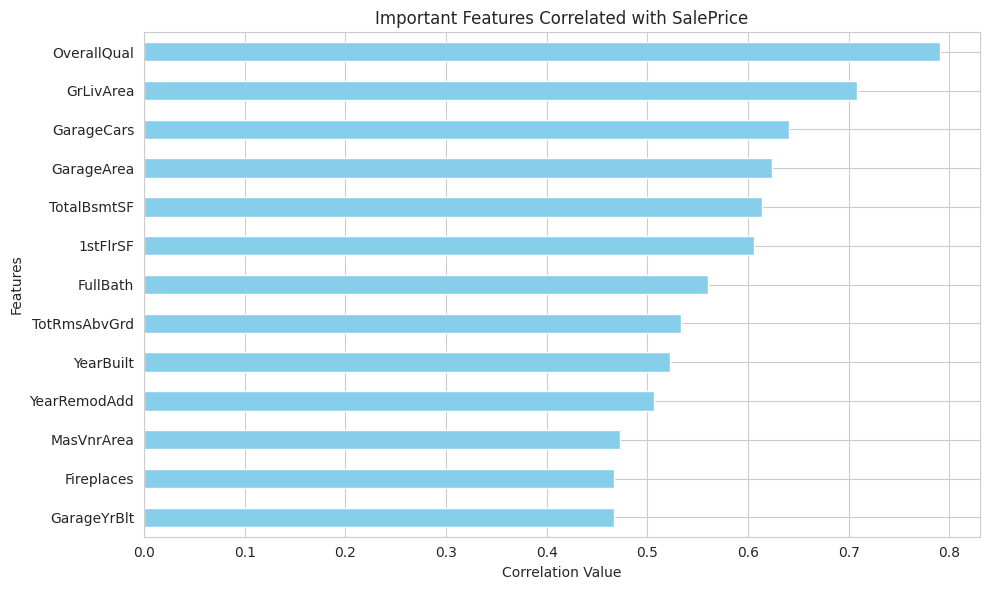

In [33]:
# STEP 33: Feature Selection

# Select features having correlation greater than 0.40
important_features = saleprice_corr[
    (saleprice_corr > 0.40) &
    (saleprice_corr.index != 'SalePrice')
]

print("Important Features for House Price Prediction:")
display(important_features)

# Plot important features
plt.figure(figsize=(10, 6))

important_features.sort_values().plot(
    kind='barh',
    color='skyblue'
)

plt.title("Important Features Correlated with SalePrice")
plt.xlabel("Correlation Value")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

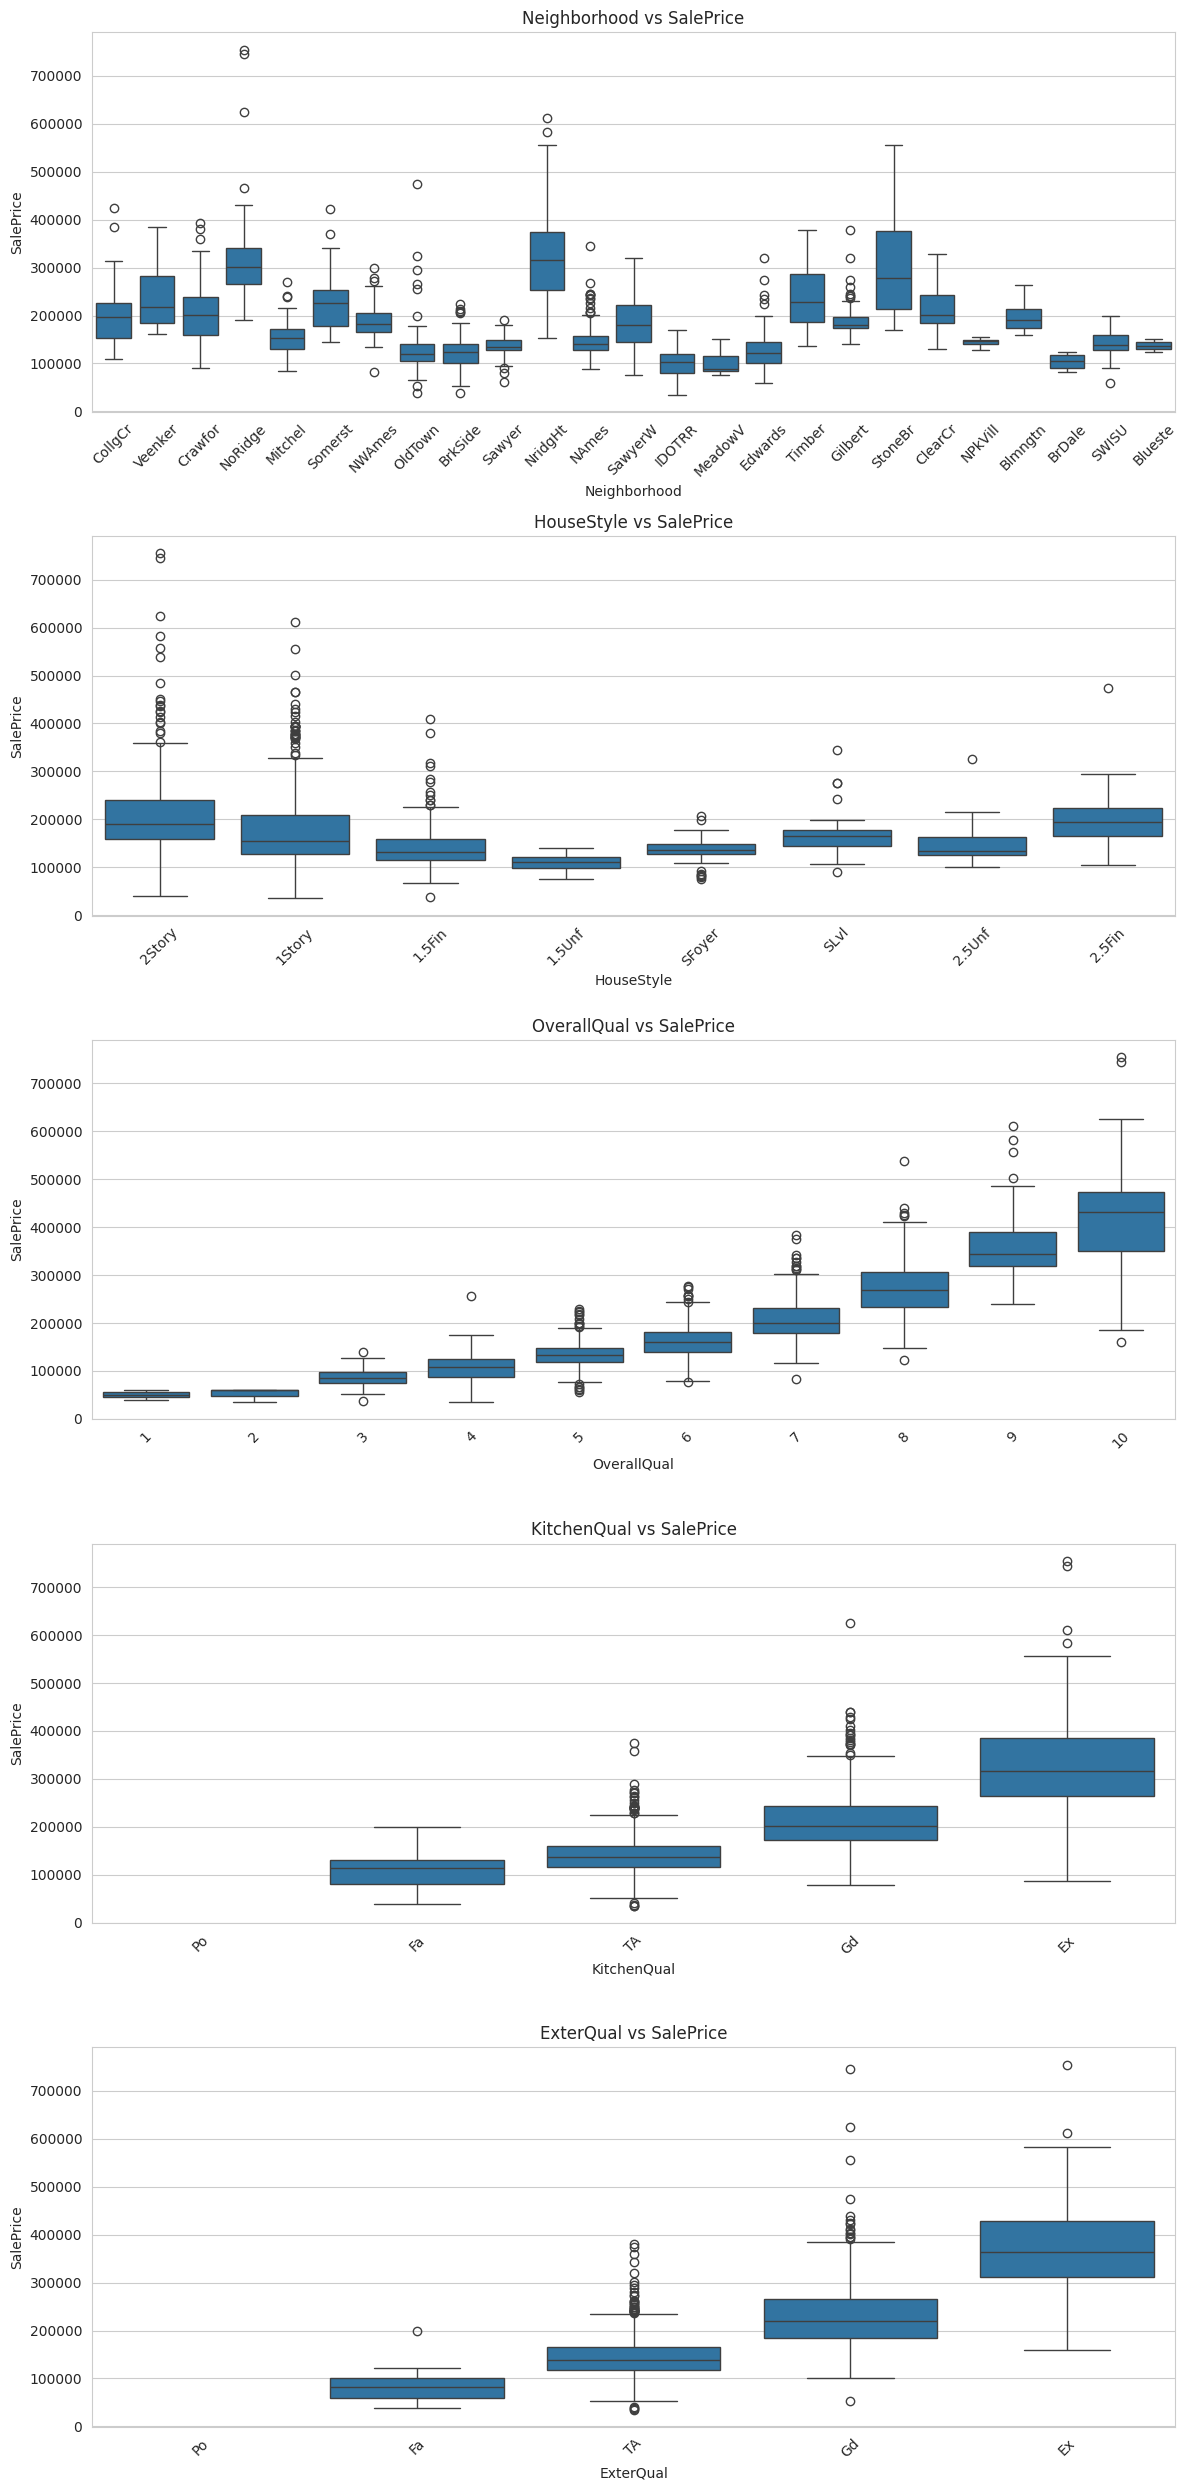

In [34]:
# STEP 34: Categorical Feature Analysis

categorical_features = [
    'Neighborhood',
    'HouseStyle',
    'OverallQual',
    'KitchenQual',
    'ExterQual'
]

# Keep only columns available in dataset
categorical_features = [
    col for col in categorical_features
    if col in cleaned_df.columns
]

# Plot categorical features against SalePrice
fig, axes = plt.subplots(
    len(categorical_features), 1,
    figsize=(12, 5 * len(categorical_features))
)

if len(categorical_features) == 1:
    axes = [axes]

for ax, column in zip(axes, categorical_features):

    sns.boxplot(
        data=cleaned_df,
        x=column,
        y='SalePrice',
        ax=ax
    )

    ax.set_title(f'{column} vs SalePrice')
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

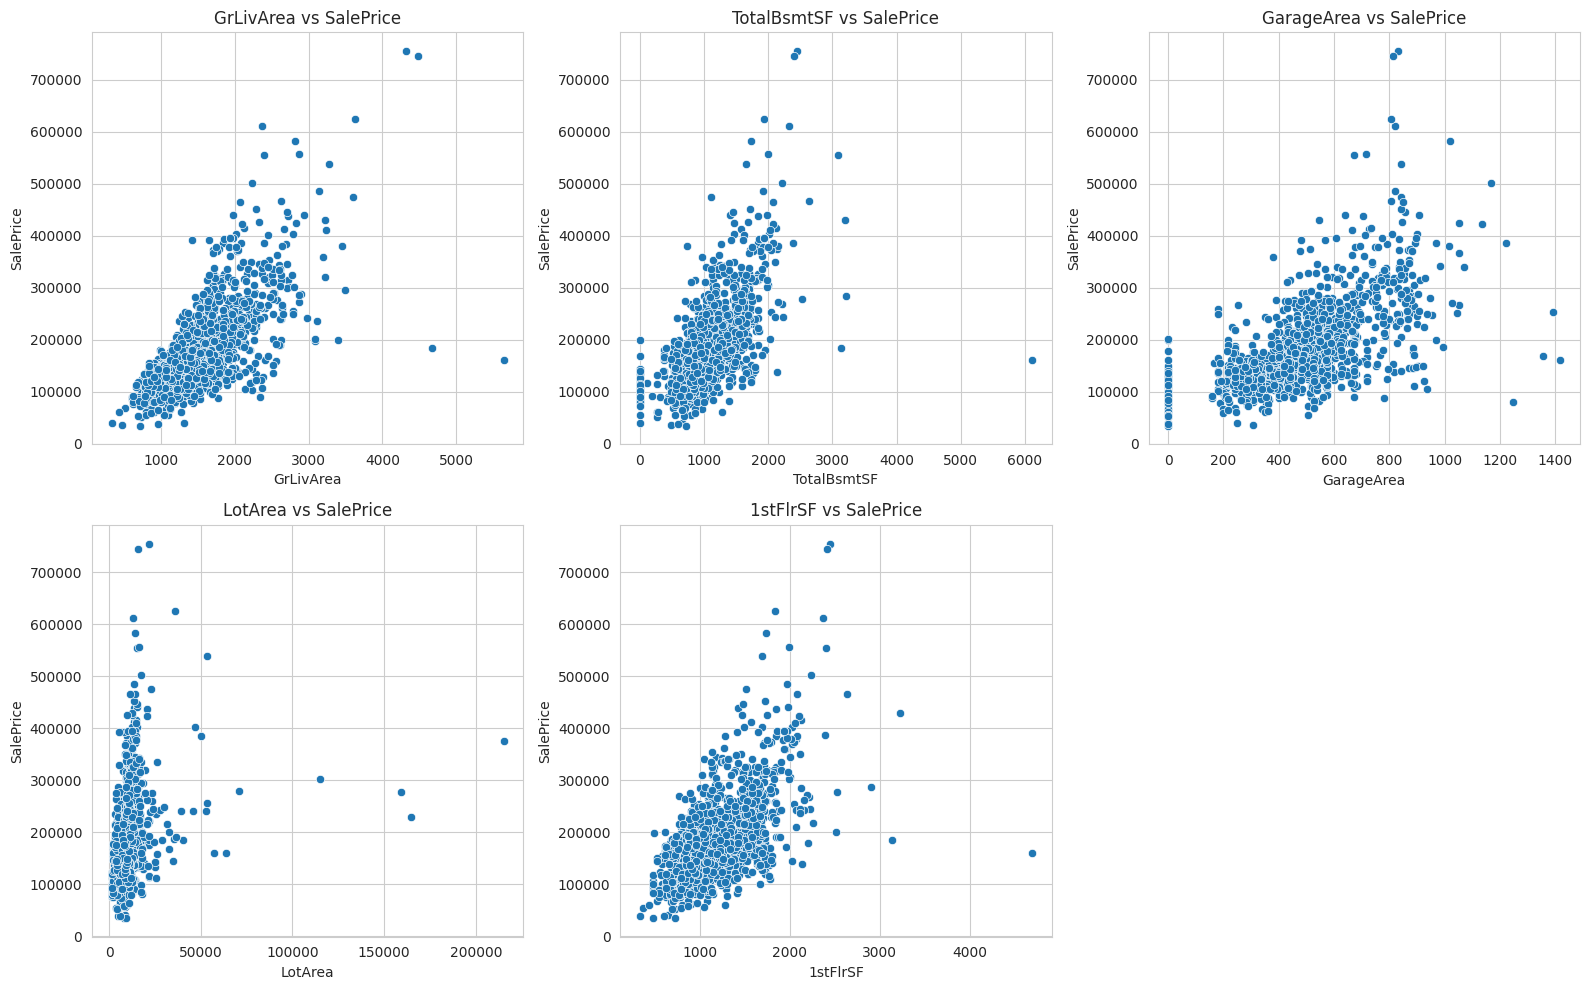

In [35]:
# STEP 35: Bivariate Analysis

# Select important numerical features
features = [
    'GrLivArea',
    'TotalBsmtSF',
    'GarageArea',
    'LotArea',
    '1stFlrSF'
]

# Create scatter plots
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

axes = axes.flatten()

for i, column in enumerate(features):

    sns.scatterplot(
        data=cleaned_df,
        x=column,
        y='SalePrice',
        ax=axes[i]
    )

    axes[i].set_title(f'{column} vs SalePrice')
    axes[i].set_xlabel(column)
    axes[i].set_ylabel('SalePrice')

# Remove unused subplot
fig.delaxes(axes[5])

plt.tight_layout()
plt.show()

In [36]:
# STEP 36: Feature Engineering

# 1. Calculate Total House Area
cleaned_df['TotalSF'] = (
    cleaned_df['TotalBsmtSF'] +
    cleaned_df['1stFlrSF'] +
    cleaned_df['2ndFlrSF']
)

# 2. Calculate Total Bathrooms
cleaned_df['TotalBathrooms'] = (
    cleaned_df['FullBath'] +
    (0.5 * cleaned_df['HalfBath']) +
    cleaned_df['BsmtFullBath'] +
    (0.5 * cleaned_df['BsmtHalfBath'])
)

# 3. Calculate House Age
cleaned_df['HouseAge'] = (
    cleaned_df['YrSold'] -
    cleaned_df['YearBuilt']
)

# 4. Calculate Years Since Remodeling
cleaned_df['YearsSinceRemod'] = (
    cleaned_df['YrSold'] -
    cleaned_df['YearRemodAdd']
)

# Display new features
new_features = [
    'TotalSF',
    'TotalBathrooms',
    'HouseAge',
    'YearsSinceRemod'
]

print("New Features Created Successfully!")

display(cleaned_df[new_features + ['SalePrice']].head())

print("\nUpdated Dataset Shape:", cleaned_df.shape)

New Features Created Successfully!


,TotalSF,TotalBathrooms,HouseAge,YearsSinceRemod,SalePrice
0,2566,3.5,5,5,208500
1,2524,2.5,31,31,181500
2,2706,3.5,7,6,223500
3,2473,2.0,91,36,140000
4,3343,3.5,8,8,250000



Updated Dataset Shape: (1460, 85)


Correlation of New Features with SalePrice:


,TotalSF,TotalBathrooms,HouseAge,YearsSinceRemod,SalePrice
TotalSF,1.000000,0.604324,-0.347892,-0.344859,0.782260
TotalBathrooms,0.604324,1.000000,-0.522595,-0.442525,0.631731
HouseAge,-0.347892,-0.522595,1.000000,0.594195,-0.523350
YearsSinceRemod,-0.344859,-0.442525,0.594195,1.000000,-0.509079
SalePrice,0.782260,0.631731,-0.523350,-0.509079,1.000000


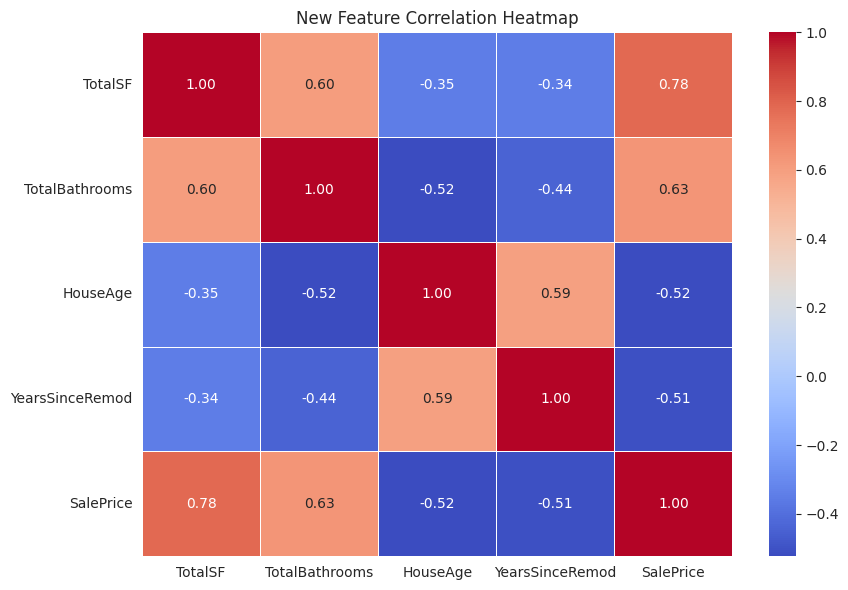

In [37]:
# STEP 37: Feature Correlation After Engineering

new_corr = cleaned_df[
    ['TotalSF', 'TotalBathrooms',
     'HouseAge', 'YearsSinceRemod', 'SalePrice']
].corr()

print("Correlation of New Features with SalePrice:")

display(new_corr)

# Visualize correlation
plt.figure(figsize=(9, 6))

sns.heatmap(
    new_corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("New Feature Correlation Heatmap")

plt.tight_layout()
plt.show()


In [38]:
# STEP 38: Prepare Data for Machine Learning

from sklearn.model_selection import train_test_split

# Separate features and target
X = cleaned_df.drop('SalePrice', axis=1)
y = cleaned_df['SalePrice']

# Identify numerical and categorical columns
numerical_columns = X.select_dtypes(
    include=['int64', 'float64']
).columns

categorical_columns = X.select_dtypes(
    include=['object', 'category']
).columns

# Display information
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nNumerical Features:", len(numerical_columns))
print("Categorical Features:", len(categorical_columns))

print("\nTarget Variable: SalePrice")

Features Shape: (1460, 84)
Target Shape: (1460,)

Numerical Features: 41
Categorical Features: 43

Target Variable: SalePrice


In [39]:
# STEP 39: Categorical Encoding and Data Preprocessing

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Remove target and ID column from input features
X = cleaned_df.drop(
    columns=['SalePrice', 'Id'],
    errors='ignore'
)

y = cleaned_df['SalePrice']

# Identify numerical and categorical columns
numerical_columns = X.select_dtypes(
    include=['int64', 'float64']
).columns

categorical_columns = X.select_dtypes(
    include=['object', 'category']
).columns

# Numerical preprocessing
numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ('num', numerical_pipeline, numerical_columns),
    ('cat', categorical_pipeline, categorical_columns)
])

# Split dataset into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Fit on training data and transform both datasets
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Data Preprocessing Completed!")

print("Training Data Shape:", X_train_processed.shape)
print("Testing Data Shape:", X_test_processed.shape)

print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

Data Preprocessing Completed!
Training Data Shape: (1168, 305)
Testing Data Shape: (292, 305)
Training Target Shape: (1168,)
Testing Target Shape: (292,)


In [40]:

# STEP 40: Train Machine Learning Models

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# Initialize models
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        random_state=42
    )
}

# Train all models
trained_models = {}

for name, model in models.items():
    model.fit(X_train_processed, y_train)
    trained_models[name] = model
    print(name, "Training Completed!")

print("\nAll Models Trained Successfully!")


Linear Regression Training Completed!
Random Forest Training Completed!
Gradient Boosting Training Completed!

All Models Trained Successfully!


In [41]:

# STEP 41: Model Evaluation

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
import pandas as pd

evaluation_results = []

for name, model in trained_models.items():

    y_pred = model.predict(X_test_processed)

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    evaluation_results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(evaluation_results)

print("MODEL EVALUATION RESULTS")
display(results_df.round(3))


MODEL EVALUATION RESULTS


,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,21126.506,4.275930e+09,65390.597,0.443
1,Random Forest,17515.827,8.629140e+08,29375.397,0.887
2,Gradient Boosting,15930.268,7.047016e+08,26546.216,0.908


Best Model: Gradient Boosting
Best R2 Score: 0.9081262542819407


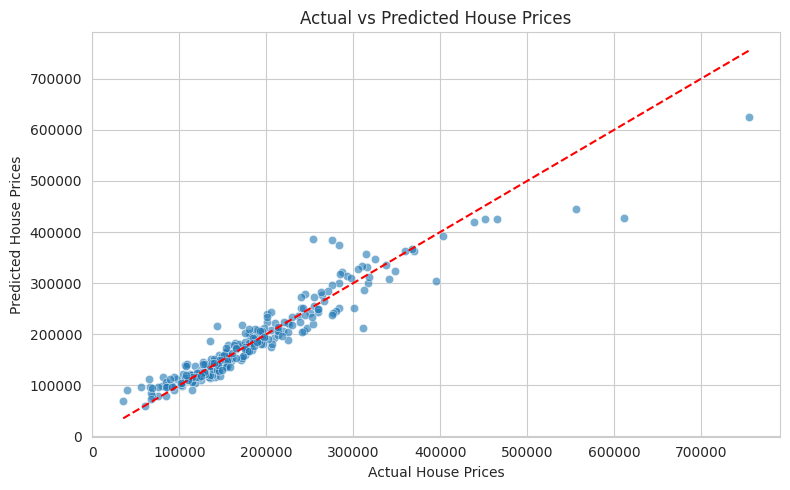

In [42]:

# STEP 42: Best Model Selection

import matplotlib.pyplot as plt
import seaborn as sns

# Select model with highest R2 Score
best_model_name = results_df.loc[
    results_df["R2 Score"].idxmax(), "Model"
]

best_model = trained_models[best_model_name]

# Generate predictions
y_pred_best = best_model.predict(X_test_processed)

print("Best Model:", best_model_name)
print("Best R2 Score:",
      results_df["R2 Score"].max())

# Actual vs Predicted Prices
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=y_test,
    y=y_pred_best,
    alpha=0.6
)

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Actual vs Predicted House Prices")

# Perfect prediction reference line
min_price = min(y_test.min(), y_pred_best.min())
max_price = max(y_test.max(), y_pred_best.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    'r--'
)

plt.tight_layout()
plt.show()


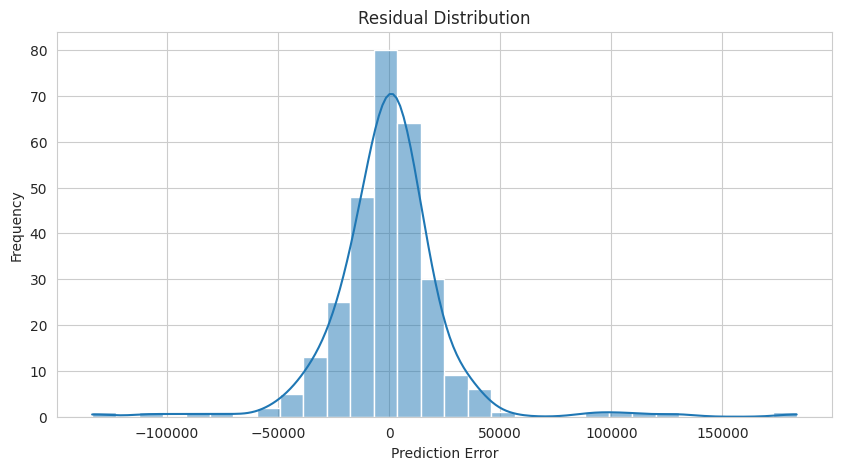

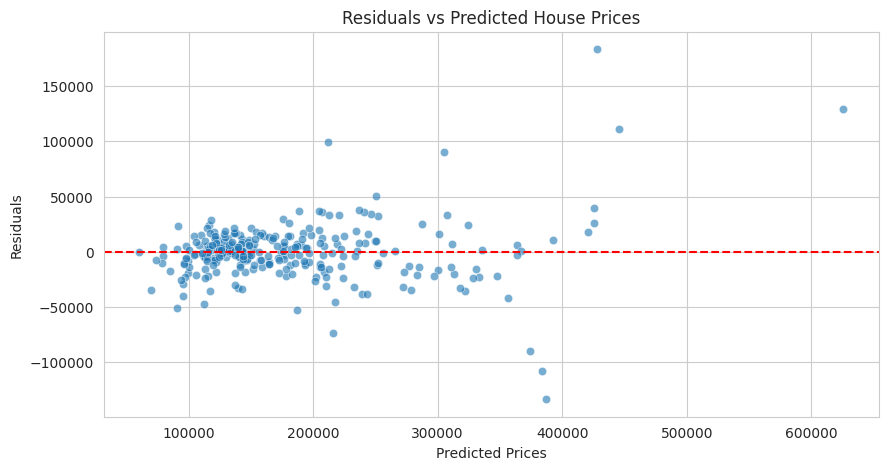

Mean Residual: -204.5406198492996
Residual Analysis Completed!


In [43]:

# STEP 43: Residual Analysis

# Calculate residuals
residuals = y_test - y_pred_best

# Plot Residual Distribution
plt.figure(figsize=(10, 5))

sns.histplot(
    residuals,
    bins=30,
    kde=True
)

plt.title("Residual Distribution")
plt.xlabel("Prediction Error")
plt.ylabel("Frequency")

plt.show()

# Actual vs Residual Plot
plt.figure(figsize=(10, 5))

sns.scatterplot(
    x=y_pred_best,
    y=residuals,
    alpha=0.6
)

plt.axhline(y=0, color='red', linestyle='--')

plt.title("Residuals vs Predicted House Prices")
plt.xlabel("Predicted Prices")
plt.ylabel("Residuals")

plt.show()

print("Mean Residual:", np.mean(residuals))
print("Residual Analysis Completed!")


TOP 15 IMPORTANT FEATURES


,Feature,Importance
36,num__TotalSF,0.333926
3,num__OverallQual,0.150840
13,num__2ndFlrSF,0.033315
25,num__GarageCars,0.019498
37,num__TotalBathrooms,0.013175
186,cat__BsmtQual_Ex,0.013097
2,num__LotArea,0.008433
4,num__OverallCond,0.007679
233,cat__KitchenQual_Ex,0.005807
15,num__GrLivArea,0.004449


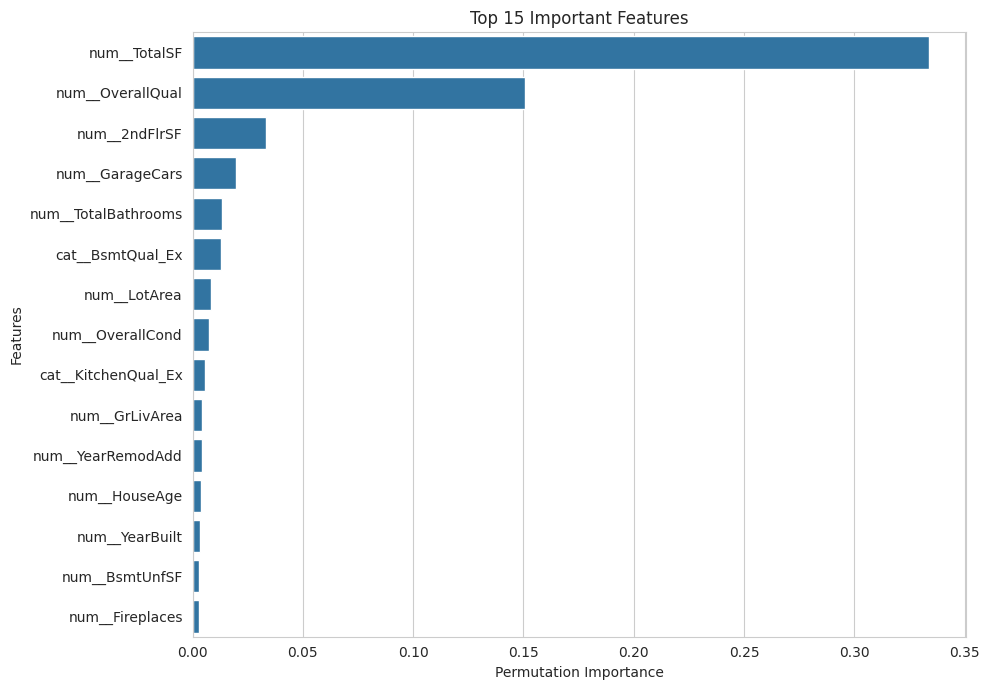

Feature Importance Analysis Completed!


In [45]:


# STEP 44: Feature Importance Analysis (Fixed)

from sklearn.inspection import permutation_importance

# Convert sparse matrix into dense array
X_test_dense = X_test_processed.toarray()

# Calculate feature importance
importance = permutation_importance(
    best_model,
    X_test_dense,
    y_test,
    n_repeats=5,
    random_state=42,
    scoring="r2"
)

# Get feature names
feature_names = preprocessor.get_feature_names_out()

# Create importance dataframe
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance.importances_mean
})

# Sort features by importance
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

# Display top 15 features
print("TOP 15 IMPORTANT FEATURES")
display(importance_df.head(15))

# Visualize feature importance
plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Important Features")
plt.xlabel("Permutation Importance")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

print("Feature Importance Analysis Completed!")


ACTUAL VS PREDICTED HOUSE PRICES


,Actual Price,Predicted Price,Difference
0,154500,143159.87,11340.13
1,325000,347453.33,-22453.33
2,115000,114833.66,166.34
3,159000,148515.97,10484.03
4,315500,331005.92,-15505.92
5,75500,79767.67,-4267.67
6,311500,212213.57,99286.43
7,146000,148036.16,-2036.16
8,84500,79877.15,4622.85
9,135500,143671.72,-8171.72


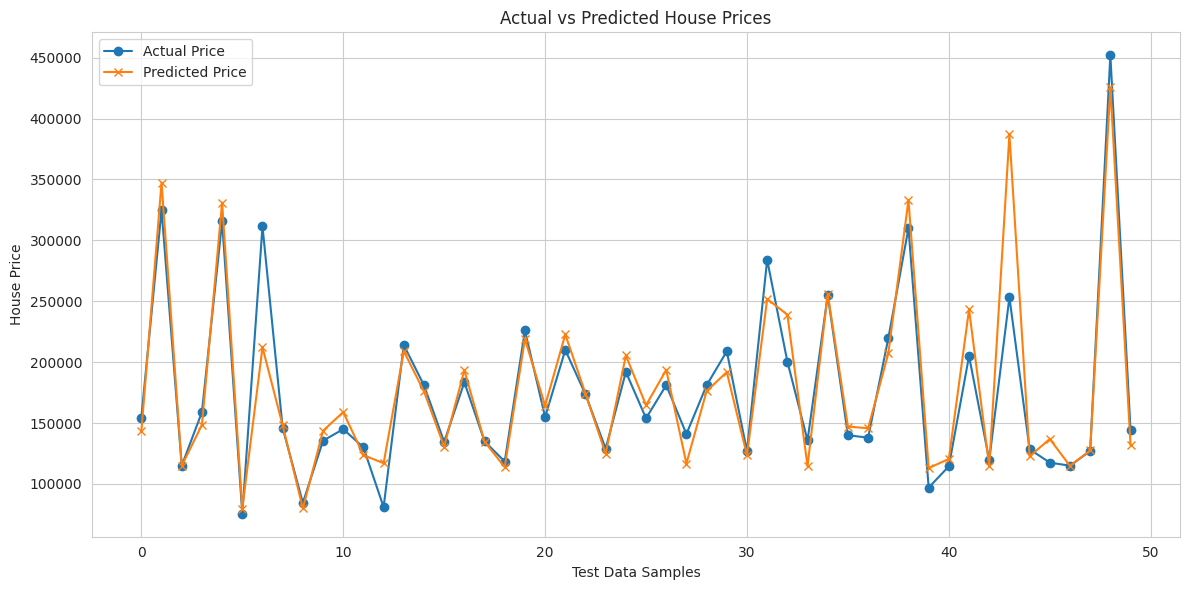

Prediction Comparison Completed!


In [46]:

# STEP 45: Actual vs Predicted Comparison

comparison_df = pd.DataFrame({
    "Actual Price": np.array(y_test),
    "Predicted Price": y_pred_best
})

# Calculate prediction error
comparison_df["Difference"] = (
    comparison_df["Actual Price"] -
    comparison_df["Predicted Price"]
)

# Display first 15 predictions
print("ACTUAL VS PREDICTED HOUSE PRICES")

display(comparison_df.head(15).round(2))

# Visualize comparison
plt.figure(figsize=(12, 6))

plt.plot(
    comparison_df["Actual Price"].values[:50],
    label="Actual Price",
    marker="o"
)

plt.plot(
    comparison_df["Predicted Price"].values[:50],
    label="Predicted Price",
    marker="x"
)

plt.title("Actual vs Predicted House Prices")
plt.xlabel("Test Data Samples")
plt.ylabel("House Price")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print("Prediction Comparison Completed!")


FINAL MODEL PERFORMANCE REPORT


,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,21126.506,4.275930e+09,65390.597,0.443
1,Random Forest,17515.827,8.629140e+08,29375.397,0.887
2,Gradient Boosting,15930.268,7.047016e+08,26546.216,0.908



BEST PERFORMING MODEL: Gradient Boosting
R2 Score: 0.9081
MAE: 15930.27
RMSE: 26546.22


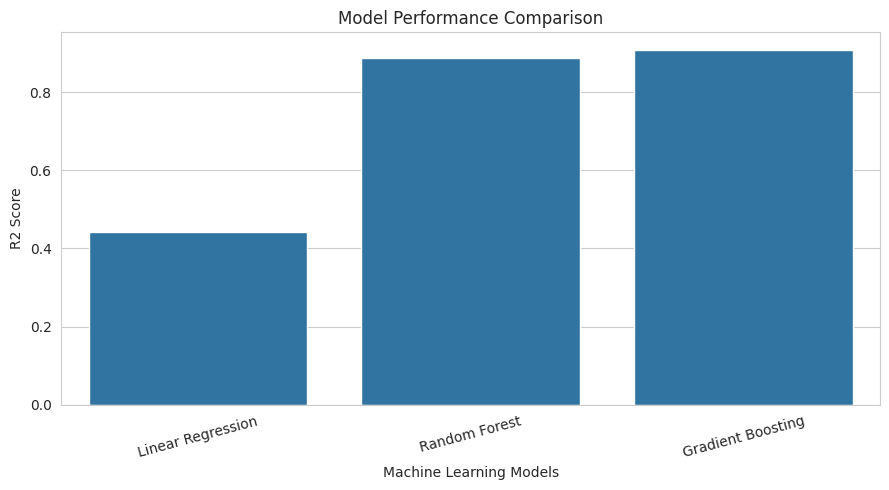


Final Model Evaluation Completed!


In [47]:

# STEP 46: Final Model Performance Summary

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Display model comparison
print("FINAL MODEL PERFORMANCE REPORT")

display(results_df.round(3))

# Identify best model
best_model_name = results_df.loc[
    results_df["R2 Score"].idxmax(), "Model"
]

best_r2 = results_df["R2 Score"].max()

best_mae = results_df.loc[
    results_df["R2 Score"].idxmax(), "MAE"
]

best_rmse = results_df.loc[
    results_df["R2 Score"].idxmax(), "RMSE"
]

print("\nBEST PERFORMING MODEL:", best_model_name)
print("R2 Score:", round(best_r2, 4))
print("MAE:", round(best_mae, 2))
print("RMSE:", round(best_rmse, 2))

# Model performance visualization
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="R2 Score"
)

plt.title("Model Performance Comparison")
plt.ylabel("R2 Score")
plt.xlabel("Machine Learning Models")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

print("\nFinal Model Evaluation Completed!")


In [48]:

# STEP 47: Save Best Model

import joblib
from google.colab import files

# Create model package
model_package = {
    "model": best_model,
    "model_name": best_model_name,
    "preprocessor": preprocessor,
    "feature_names": preprocessor.get_feature_names_out()
}

# Save model and preprocessing together
joblib.dump(
    model_package,
    "house_price_prediction_model.pkl"
)

print("Best Model:", best_model_name)
print("Model Saved Successfully!")

# Download saved model
files.download("house_price_prediction_model.pkl")


Best Model: Gradient Boosting
Model Saved Successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Project Conclusion

The House Price Prediction project successfully demonstrates Exploratory Data Analysis (EDA), data cleaning, feature engineering, data preprocessing, and machine learning model development.

Three machine learning algorithms were implemented:
1. Linear Regression
2. Random Forest Regressor
3. Gradient Boosting Regressor

The models were evaluated using MAE, MSE, RMSE, and R² Score to identify the best-performing model.

The project also included data visualization, outlier detection, correlation analysis, feature importance analysis, and actual-versus-predicted price comparison.

**Final Outcome:** A machine learning model was developed to predict house prices based on different property features.

# Project Conclusion

The House Price Prediction project successfully demonstrates Exploratory Data Analysis (EDA), data cleaning, feature engineering, data preprocessing, and machine learning model development.

Three machine learning algorithms were implemented:
1. Linear Regression
2. Random Forest Regressor
3. Gradient Boosting Regressor

The models were evaluated using MAE, MSE, RMSE, and R² Score to identify the best-performing model.

The project also included data visualization, outlier detection, correlation analysis, feature importance analysis, and actual-versus-predicted price comparison.

**Final Outcome:** A machine learning model was developed to predict house prices based on different property features.